<a href="https://colab.research.google.com/github/chandrahzzz/EDA-COURSE/blob/main/pca23bds0308.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

23BDS0308
PCA

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
# Load the dataset
df = pd.read_csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/catholic.csv")
print(df.shape)
df.head(10)

(7430, 14)


,rownames,id,read12,math12,female,asian,hispan,black,motheduc,fatheduc,lfaminc,hsgrad,cathhs,parcath
0,1,124902,61.41,49.77,0,0,0,0,14.0,12.0,10.308950,1.0,0,1
1,2,124915,58.34,59.84,0,0,0,0,14.0,14.0,10.308950,1.0,0,1
2,3,124916,59.33,50.38,1,0,0,0,14.0,11.0,10.308950,1.0,0,1
3,4,124932,49.59,45.03,1,0,0,0,12.0,14.0,10.308950,1.0,0,1
4,5,124944,57.62,54.26,1,0,0,0,12.0,12.0,10.657260,1.0,0,1
5,6,124947,52.53,56.73,1,0,0,0,12.0,11.0,11.042920,1.0,0,1
6,7,124966,60.12,55.37,1,0,0,0,14.0,14.0,9.433484,1.0,0,1
7,8,124968,64.69,65.07,0,0,0,0,14.0,14.0,10.308950,1.0,0,1
8,9,124972,42.09,53.98,0,0,0,0,14.0,14.0,10.308950,1.0,0,1
9,10,124974,60.23,62.72,0,0,0,0,14.0,12.0,9.769957,1.0,0,1


In [3]:
# Understand the dataset: structure, missing and unique values
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nUnique values:\n", df.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7430 entries, 0 to 7429
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  7430 non-null   int64  
 1   id        7430 non-null   int64  
 2   read12    7430 non-null   float64
 3   math12    7430 non-null   float64
 4   female    7430 non-null   int64  
 5   asian     7430 non-null   int64  
 6   hispan    7430 non-null   int64  
 7   black     7430 non-null   int64  
 8   motheduc  7430 non-null   float64
 9   fatheduc  7430 non-null   float64
 10  lfaminc   7430 non-null   float64
 11  hsgrad    5970 non-null   float64
 12  cathhs    7430 non-null   int64  
 13  parcath   7430 non-null   int64  
dtypes: float64(6), int64(8)
memory usage: 812.8 KB

Missing values:
 rownames       0
id             0
read12         0
math12         0
female         0
asian          0
hispan         0
black          0
motheduc       0
fatheduc       0
lfaminc        0
hsgrad      

In [4]:
# Clean the data and choose the PCA variables
df = df.drop(columns=["rownames", "id"])
pca_vars = ["read12", "math12", "motheduc", "fatheduc", "lfaminc"]
df["gender"] = df["female"].map({0: "Male", 1: "Female"})
df["school"] = df["cathhs"].map({0: "Non-Catholic HS", 1: "Catholic HS"})
df["parent"] = df["parcath"].map({0: "Parent not Catholic", 1: "Parent Catholic"})
df["race"] = np.select([df.asian == 1, df.hispan == 1, df.black == 1], ["Asian", "Hispanic", "Black"], "White/Other")
df["hsgrad_f"] = df["hsgrad"].map({0: "Not grad", 1: "Grad"}).fillna("NA")
X = df[pca_vars].dropna()
print("Rows used for PCA:", len(X))

Rows used for PCA: 7430


      read12  math12  motheduc  fatheduc  lfaminc
mean   51.77   52.13     13.36     13.67    10.35
std     9.41    9.46      2.01      2.27     0.79
min    29.15   29.50      8.00      8.00     6.21
max    68.09   71.37     18.00     18.00    12.35


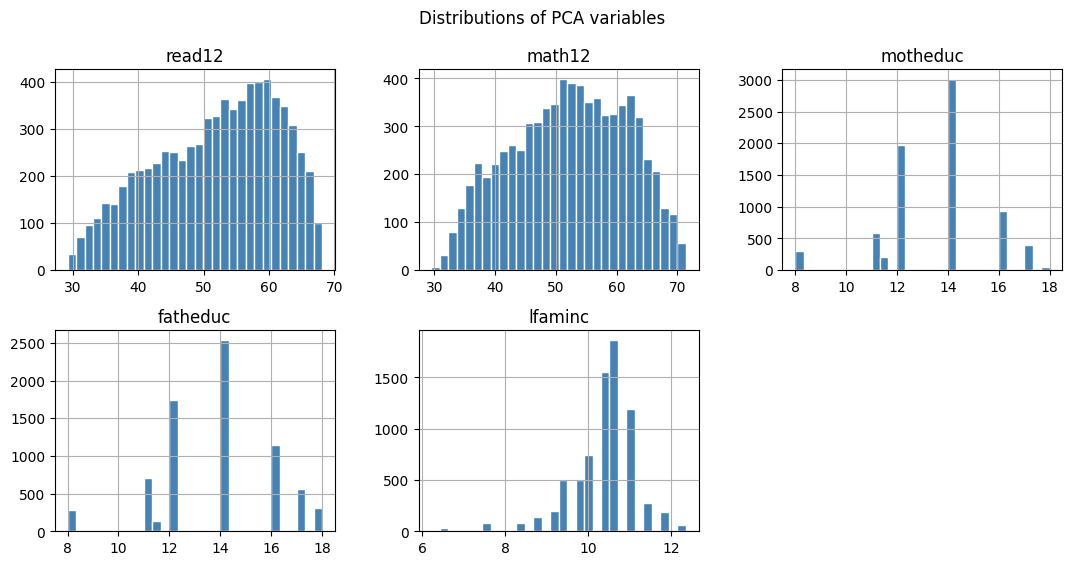

In [5]:
# Check scales and distributions
print(X.agg(["mean", "std", "min", "max"]).round(2))
X.hist(bins=30, figsize=(13, 6), color="steelblue", edgecolor="white", layout=(2, 3))
plt.suptitle("Distributions of PCA variables")
plt.show()

          read12  math12  motheduc  fatheduc  lfaminc
read12     1.000   0.710     0.285     0.317    0.259
math12     0.710   1.000     0.342     0.375    0.316
motheduc   0.285   0.342     1.000     0.583    0.405
fatheduc   0.317   0.375     0.583     1.000    0.446
lfaminc    0.259   0.316     0.405     0.446    1.000


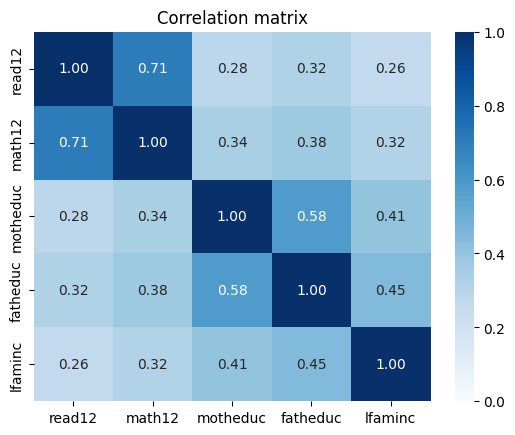

In [6]:
# Correlation matrix
R = X.corr()
print(R.round(3))
sns.heatmap(R, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Correlation matrix")
plt.show()

In [7]:
# Suitability for PCA: Bartlett's test and KMO
n, p = X.shape
chi2 = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(R))
print(f"Bartlett chi-square = {chi2:.2f}, df = {p * (p - 1) // 2}, p-value = {stats.chi2.sf(chi2, p * (p - 1) / 2):.4g}")
Rinv = np.linalg.inv(R)
P = -Rinv / np.sqrt(np.outer(np.diag(Rinv), np.diag(Rinv)))
R0 = R.values.copy()
np.fill_diagonal(R0, 0)
np.fill_diagonal(P, 0)
print(f"Overall KMO = {(R0**2).sum() / ((R0**2).sum() + (P**2).sum()):.3f}")
pd.Series((R0**2).sum(0) / ((R0**2).sum(0) + (P**2).sum(0)), index=pca_vars, name="MSA").round(3)

Bartlett chi-square = 11809.68, df = 10, p-value = 0
Overall KMO = 0.704


,MSA
read12,0.632
math12,0.650
motheduc,0.742
fatheduc,0.736
lfaminc,0.839


In [8]:
# Run PCA on standardized data: eigenvalues and variance explained
Z = StandardScaler().fit_transform(X)
pca = PCA().fit(Z)
scores = pca.transform(Z)
eig = pd.DataFrame({"PC": [f"PC{i + 1}" for i in range(p)], "Eigenvalue": pca.explained_variance_,
                    "Variance %": pca.explained_variance_ratio_ * 100})
eig["Cumulative %"] = eig["Variance %"].cumsum()
eig.round(3)

,PC,Eigenvalue,Variance %,Cumulative %
0,PC1,2.622,52.441,52.441
1,PC2,1.054,21.075,73.516
2,PC3,0.626,12.511,86.027
3,PC4,0.413,8.262,94.289
4,PC5,0.286,5.711,100.000


Kaiser rule (eigenvalue > 1): 2 components
80% cumulative variance rule: 3 components


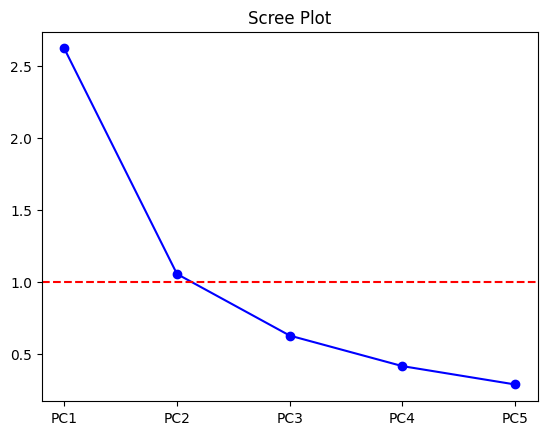

In [9]:
# How many components to keep: Kaiser rule, 80% rule and scree plot
k_kaiser = (eig["Eigenvalue"] > 1).sum()
print("Kaiser rule (eigenvalue > 1):", k_kaiser, "components")
print("80% cumulative variance rule:", (eig["Cumulative %"] >= 80).idxmax() + 1, "components")
k = max(2, k_kaiser)
plt.plot(eig["PC"], eig["Eigenvalue"], "bo-")
plt.axhline(1, color="red", ls="--")
plt.title("Scree Plot")
plt.show()

In [10]:
# Loadings, variable-PC correlations and contributions
loadings = pd.DataFrame(pca.components_.T, index=pca_vars, columns=eig["PC"])
var_cor = loadings * np.sqrt(pca.explained_variance_)
contrib = 100 * loadings**2
print("Loadings:\n", loadings.round(3))
print("\nCorrelation with PCs:\n", var_cor.iloc[:, :k].round(3))
print("\nContribution (%):\n", contrib.iloc[:, :k].round(1))

Loadings:
 PC          PC1    PC2    PC3    PC4    PC5
read12    0.442  0.580 -0.003 -0.021 -0.684
math12    0.474  0.496  0.011 -0.019  0.727
motheduc  0.446 -0.400 -0.459 -0.656 -0.029
fatheduc  0.467 -0.367 -0.293  0.748 -0.031
lfaminc   0.403 -0.351  0.839 -0.097 -0.039

Correlation with PCs:
 PC          PC1    PC2
read12    0.715  0.596
math12    0.768  0.509
motheduc  0.723 -0.410
fatheduc  0.757 -0.377
lfaminc   0.653 -0.360

Contribution (%):
 PC         PC1   PC2
read12    19.5  33.7
math12    22.5  24.6
motheduc  19.9  16.0
fatheduc  21.8  13.5
lfaminc   16.2  12.3


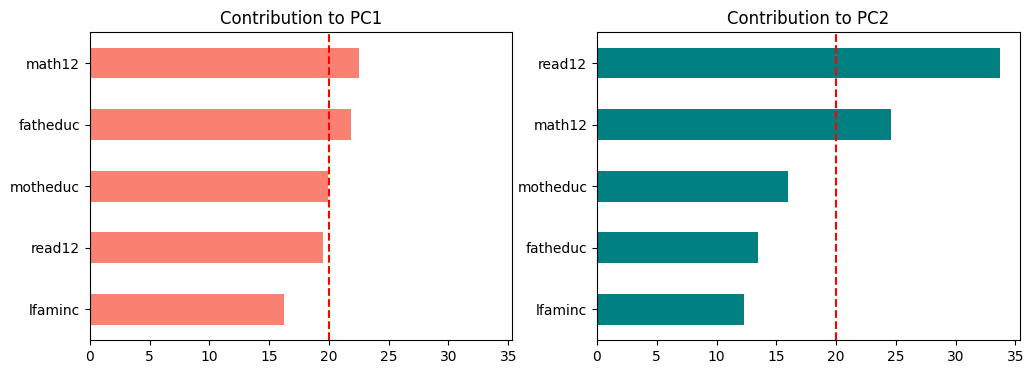

In [11]:
# Variable contributions to PC1 and PC2
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for i, c in enumerate(["salmon", "teal"]):
    contrib.iloc[:, i].sort_values().plot.barh(ax=ax[i], color=c, title=f"Contribution to PC{i + 1}")
    ax[i].axvline(100 / p, color="red", ls="--")
plt.show()

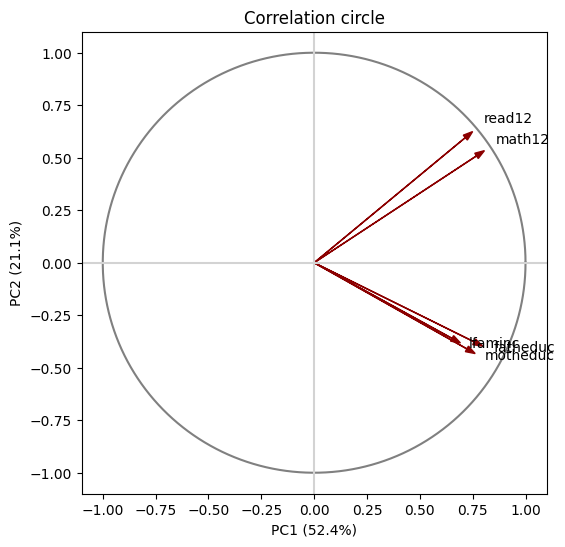

In [12]:
# Correlation circle
t = np.linspace(0, 2 * np.pi, 200)
plt.figure(figsize=(6, 6))
plt.plot(np.cos(t), np.sin(t), color="grey")
for v in pca_vars:
    plt.arrow(0, 0, var_cor.loc[v, "PC1"], var_cor.loc[v, "PC2"], color="darkred", head_width=0.03)
    plt.text(var_cor.loc[v, "PC1"] * 1.12, var_cor.loc[v, "PC2"] * 1.12, v)
plt.axhline(0, color="lightgrey")
plt.axvline(0, color="lightgrey")
plt.xlabel(f"PC1 ({eig['Variance %'][0]:.1f}%)")
plt.ylabel(f"PC2 ({eig['Variance %'][1]:.1f}%)")
plt.title("Correlation circle")
plt.show()

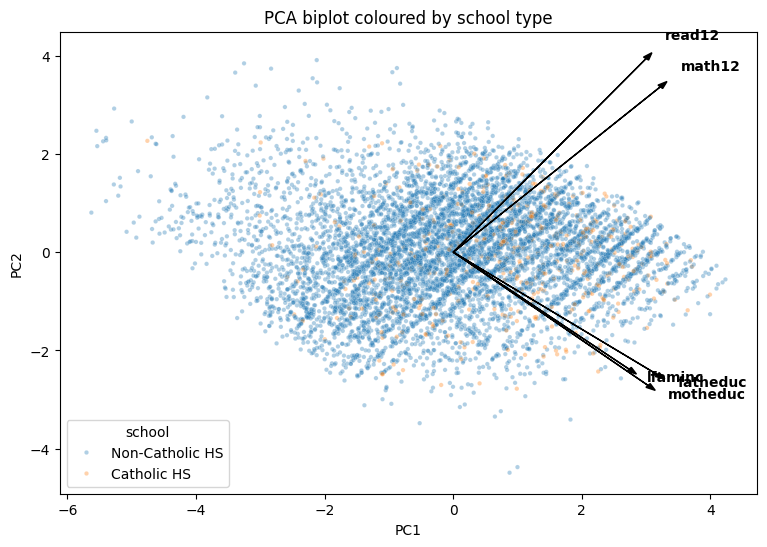

In [13]:
# Add PC scores to the data and draw the biplot coloured by school type
df_pca = df.loc[X.index].copy()
df_pca["PC1"], df_pca["PC2"] = scores[:, 0], scores[:, 1]
sc = np.abs(scores[:, :2]).max() / np.abs(loadings.iloc[:, :2].values).max() * 0.7
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="school", alpha=0.35, s=10)
for v in pca_vars:
    plt.arrow(0, 0, loadings.loc[v, "PC1"] * sc, loadings.loc[v, "PC2"] * sc, color="black", head_width=0.1)
    plt.text(loadings.loc[v, "PC1"] * sc * 1.1, loadings.loc[v, "PC2"] * sc * 1.1, v, fontweight="bold")
plt.title("PCA biplot coloured by school type")
plt.show()

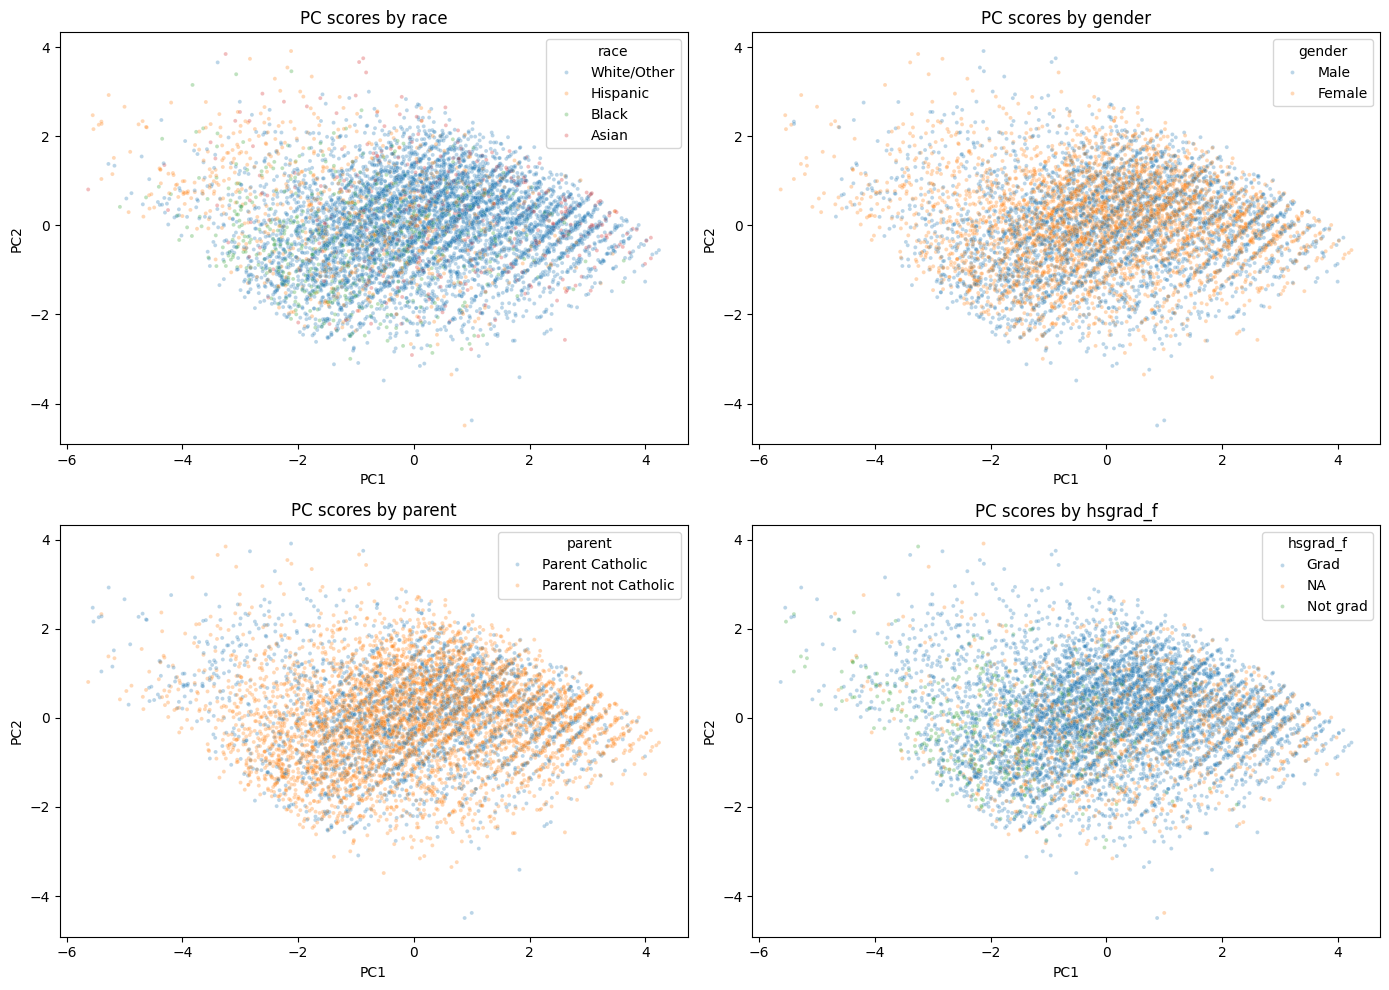

In [14]:
# PC scores by race, gender, parent's religion and graduation
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, g in zip(axes.flat, ["race", "gender", "parent", "hsgrad_f"]):
    sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue=g, alpha=0.3, s=8, ax=ax)
    ax.set_title(f"PC scores by {g}")
plt.tight_layout()
plt.show()

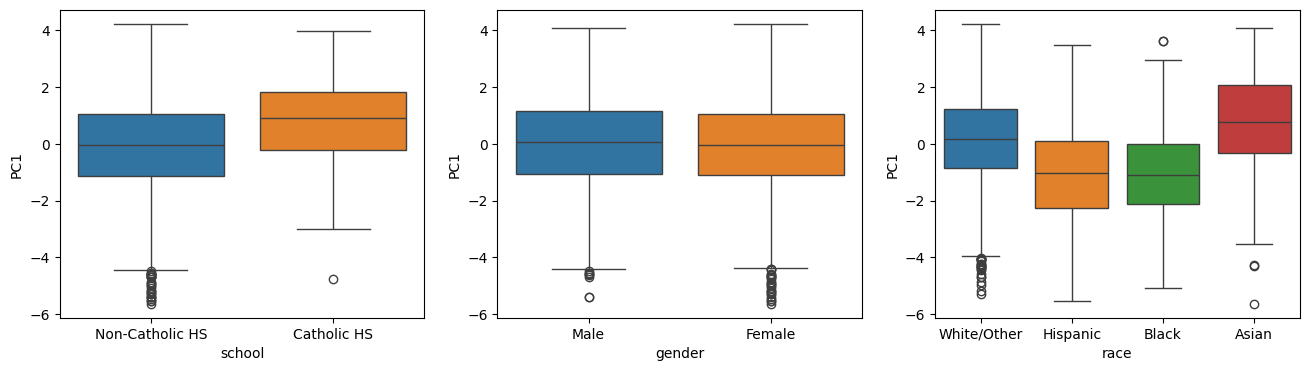

                  PC1             PC2          
                count      mean count      mean
school                                         
Catholic HS       452  0.779601   452 -0.084075
Non-Catholic HS  6978 -0.050499  6978  0.005446


TtestResult(statistic=np.float64(-12.009000743893585), pvalue=np.float64(1.4685697954943354e-29), df=np.float64(531.0158264180909))

In [15]:
# PC1 by group and Welch t-test between school types
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, g in zip(axes, ["school", "gender", "race"]):
    sns.boxplot(data=df_pca, x=g, y="PC1", hue=g, legend=False, ax=ax)
plt.show()
print(df_pca.groupby("school")[["PC1", "PC2"]].agg(["count", "mean"]))
stats.ttest_ind(df_pca.loc[df_pca.school == "Non-Catholic HS", "PC1"],
                df_pca.loc[df_pca.school == "Catholic HS", "PC1"], equal_var=False)